In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("movies.csv")

print(df.shape"\n")              # rows, columns
print(df.head()"\n")
print(df.info()"\n")             # dtypes + non-null counts
print(df.describe()"\n")         # summary stats for numeric fields

# Missing values and zeros
print(df.isnull().sum())
print((df["budget"] == 0).sum(), (df["revenue"] == 0).sum())

(2000, 7)
      budget    revenue  popularity  runtime  vote_average    title  \
0   57755036  107323371   60.377360       98      6.611888  Movie 1   
1  192100010  342896533   86.289857       96      7.184687  Movie 2   
2  128521863  253206827   86.995324      148      3.542978  Movie 3   
3  156299516   89635602   72.710096      118      5.985176  Movie 4   
4  148532820  221133868   74.829585      161      4.578480  Movie 5   

                               genres  
0  [{'id': 10749, 'name': 'Romance'}]  
1       [{'id': 18, 'name': 'Drama'}]  
2      [{'id': 35, 'name': 'Comedy'}]  
3       [{'id': 18, 'name': 'Drama'}]  
4      [{'id': 35, 'name': 'Comedy'}]  
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   budget        2000 non-null   int64  
 1   revenue       2000 non-null   int64  
 2   popularity    2000 non-null   float64
 3   runtime 

In [2]:
import ast

# --- Target (Stage 1, Q3) ---
df["success"] = (df["revenue"] > df["budget"]).astype(int)
print(df["success"].value_counts())
print(df["success"].value_counts(normalize=True))   # proportion successful

# --- Genres (Stage 1, Q4) ---
# Turn the string into a real list, then pull out just the names
df["genre_list"] = df["genres"].apply(
    lambda s: [g["name"] for g in ast.literal_eval(s)]
)

# Check: do any movies have more than one genre?
print(df["genre_list"].apply(len).value_counts())
print(df[["title", "genre_list"]].head())

# One row per (movie, genre), handy for EDA and the sidebar filter
genres_exploded = df.explode("genre_list").rename(columns={"genre_list": "genre"})
print(genres_exploded["genre"].value_counts())

success
1    1614
0     386
Name: count, dtype: int64
success
1    0.807
0    0.193
Name: proportion, dtype: float64
genre_list
1    1819
0     181
Name: count, dtype: int64
     title genre_list
0  Movie 1  [Romance]
1  Movie 2    [Drama]
2  Movie 3   [Comedy]
3  Movie 4    [Drama]
4  Movie 5   [Comedy]
genre
Romance            220
Adventure          207
Science Fiction    205
Animation          203
Comedy             202
Horror             199
Drama              197
Thriller           194
Action             192
Name: count, dtype: int64


In [3]:
# Replace empty genre lists with "Unknown" instead of dropping 181 movies
df["genre"] = df["genre_list"].apply(lambda g: g[0] if len(g) > 0 else "Unknown")
print(df["genre"].value_counts())

# Success rate by genre (a preview of Stage 2)
print(df.groupby("genre")["success"].mean().sort_values(ascending=False))

# Still need this from last time
print(df.describe())

genre
Romance            220
Adventure          207
Science Fiction    205
Animation          203
Comedy             202
Horror             199
Drama              197
Thriller           194
Action             192
Unknown            181
Name: count, dtype: int64
genre
Drama              0.822335
Horror             0.819095
Animation          0.812808
Unknown            0.812155
Comedy             0.811881
Thriller           0.809278
Romance            0.809091
Adventure          0.801932
Action             0.786458
Science Fiction    0.785366
Name: success, dtype: float64
             budget       revenue   popularity      runtime  vote_average  \
count  2.000000e+03  2.000000e+03  2000.000000  2000.000000   2000.000000   
mean   1.019211e+08  1.780574e+08    50.090738   129.568000      6.036764   
std    5.682795e+07  1.293879e+08    28.482104    28.906507      1.743093   
min    1.070640e+06  1.138729e+06     1.018466    80.000000      3.008133   
25%    5.274832e+07  7.458306e+07    

In [4]:
# Show all columns, no "..." in the middle, and round to 2 decimals
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

print("=== SUMMARY STATISTICS ===")
print(df[["budget", "revenue", "popularity", "runtime", "vote_average", "success"]].describe().T)
print("\n")   # \n adds a blank line

print("=== SUCCESS RATE BY GENRE ===")
print(df.groupby("genre")["success"].mean().sort_values(ascending=False))
print("\n")

=== SUMMARY STATISTICS ===
                count           mean            std          min           25%            50%            75%            max
budget       2,000.00 101,921,134.40  56,827,954.45 1,070,640.00 52,748,322.25 102,602,308.50 150,796,203.75 199,987,907.00
revenue      2,000.00 178,057,426.14 129,387,926.69 1,138,729.00 74,583,058.75 148,488,152.50 262,367,860.25 574,490,131.00
popularity   2,000.00          50.09          28.48         1.02         25.72          50.21          74.93          99.76
runtime      2,000.00         129.57          28.91        80.00        104.00         130.00         155.00         179.00
vote_average 2,000.00           6.04           1.74         3.01          4.58           6.05           7.58           9.00
success      2,000.00           0.81           0.39         0.00          1.00           1.00           1.00           1.00


=== SUCCESS RATE BY GENRE ===
genre
Drama             0.82
Horror            0.82
Animation         0.8

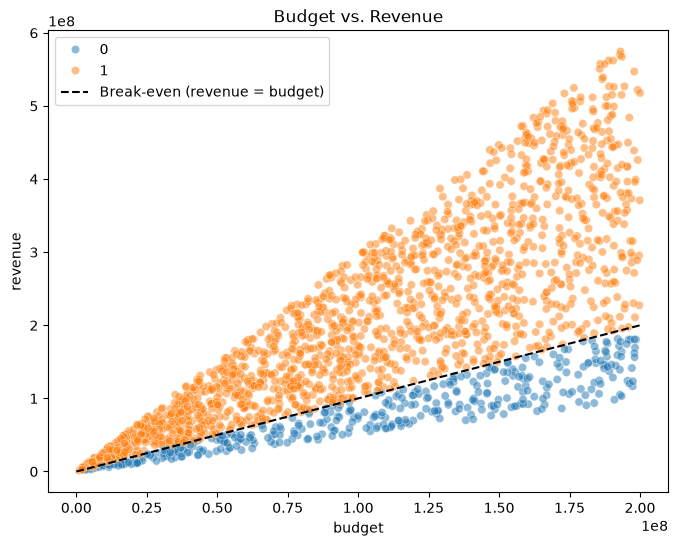

         budget  revenue
budget     1.00     0.76
revenue    0.76     1.00


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("assets", exist_ok=True)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="budget", y="revenue", hue="success", alpha=0.5)
plt.plot([0, df["budget"].max()], [0, df["budget"].max()],
         "k--", label="Break-even (revenue = budget)")
plt.title("Budget vs. Revenue")
plt.legend()
plt.savefig("assets/budget_vs_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

print(df[["budget", "revenue"]].corr())